# Do offensive passing profiles persist?
## tl;dr
**Yes, enough to justify a cautious player-comparison prototype. This does not validate fixed archetypes or interchangeable players.**

In the main 2026 check, **43 players** had at least 100 throws and 100 completed catches in each period. Their later profiles resembled their own earlier profiles more than **90.9% of other players' earlier profiles**, on average (95% team-bootstrap interval: **86.9–94.0%**). A random identity assignment would average 50%.

Their own earlier profile was the single closest match for **10 of 43 players (23.3%)**, among 81 earlier-qualified candidates; random matching would average 1.2%. Among the 32 players with at least four qualified candidates on their team, **23 (71.9%)** matched themselves first, versus 20.9% expected from random matching within those teams.

The broader 50-throw/50-catch sample contains **146 players** and gives a similar 90.5% average self-similarity percentile. Earlier seasons also show persistence. An exploratory follow-up found that five cross-team neighbors selected using early profiles averaged the **69.9th later-similarity percentile**, versus the 50th percentile expected for random selections. Those are overlapping player comparisons, not independent trials.

The practical next question is **“Which players have similar recorded offensive tendencies, and where do they differ?”** A coach could use this to narrow scouting or replacement candidates for film review. Whether a replacement succeeds remains untested. Hucks can stay in the profile as one trait.

Source: October 12, 2026 CSV exports, regular seasons 2021–2026. No live data was downloaded for this test. The primary 2026 season was inspected in prior work, so this is exploratory historical validation.

## Context & Methods
**Decision:** Is broader offensive-role comparison worth developing after individual huck-zone advantages failed to hold up reliably?

The first hurdle is repeatability: does a player's early-season profile resemble their later profile more than other players' profiles? The second, exploratory hurdle is whether similarities between different players also persist.

The primary split uses actual game dates: **before June 6, 2026** versus **June 6 onward**, covering 61 earlier and 70 later recorded regular-season games. The split date is the median recorded-game date, selected without using player outcomes. Whole games stay together. The same rule is repeated for 2023–2025; a separate check compares all of 2025 with all of 2026.

Primary eligibility requires at least **100 throws and 100 completed catches**, spanning at least **three games in each role in each period**, and one team within the season. The reference pool includes all 81 earlier-qualified players, including players who do not qualify later; 43 players qualify for evaluation in both periods. This is a study of frequently involved players, not the entire league. The 50-event and 150-event checks assess sensitivity to the volume floor. The across-season check requires 200 throws and catches and six games in each season.

Nine traits are divided into four equally weighted groups:
- Passing choices: share of short throws, hucks, forward throws and backward throws.
- Release locations: average Y position and share near either sideline.
- Catch locations: average Y position and share near either sideline, using completed named catches.
- Disc involvement: throws divided by throws plus completed catches. This is a touch-balance measure, not playing time or possession share.

Each trait is standardized using only the earlier-qualified reference players. Similarity is the square root of the equally weighted group averages of squared standardized differences. Player names, IDs, team labels, completion rates, aEC and absolute event counts are not similarity features. IDs are used only to verify identities; counts determine eligibility.

### Key Assumptions
Y runs from 0 to 120, always attacking toward 120. Short means flight distance ≤10 yards. A huck requires gain >30 yards and flight distance >40 yards. Forward/backward mean within less than 45° of the respective long-axis direction; 45° ties and zero-length throws fall into neither category. A sideline event has |X|≥15 yards. These are fixed descriptive choices, not optimized boundaries.

Completion means no recorded turnover. Catch profiles omit unsuccessful targets; they do not describe every receiving route. Stalls, invalid coordinates and unclassified-season events are excluded. A completed catch from an unnamed thrower can still contribute to the named receiver's profile. Same-name IDs are not merged.

The bootstrap resamples entire reference teams 5,000 times and averages player-level results. It is conditional on the fixed candidate pool and profiles; it does not propagate all game, opponent or measurement dependence. Intervals are omitted for fewer than 10 teams. Season checks share players and are not independent replications. Results cannot establish causal coaching tactics, off-disc roles, player quality or lineup compatibility.

In [1]:
from pathlib import Path
import contextlib, io, json, sys
import pandas as pd

project = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / 'analysis/passing_profile_validation.py').exists())
sys.path.insert(0, str(project / 'analysis'))
import passing_profile_validation as study
import passing_profile_checks as checks

RERUN_ANALYSIS = True
if RERUN_ANALYSIS:
    with contextlib.redirect_stdout(io.StringIO()):
        result = study.run()
else:
    result = json.loads((project / 'analysis/passing_profile_validation.json').read_text())
primary = result['studies'][-1]
assert primary['evaluatedPlayers'] == 43 and primary['referencePlayers'] == 81
assert round(primary['fractionOfOtherPlayersBeaten']['mean']*100, 1) == 90.9
print('Source: data/database-exports/2026-10-12/{throws,games,players,teams}.csv')
print('Read-only inputs; source hashes checked against the export manifest.')
print('Reproduce: python3 analysis/build_passing_profile_notebook.py (numpy and pandas required).')

Source: data/database-exports/2026-10-12/{throws,games,players,teams}.csv
Read-only inputs; source hashes checked against the export manifest.
Reproduce: python3 analysis/build_passing_profile_notebook.py (numpy and pandas required).


## Data
The full audited scope contains 456,555 named nonstall throws and 425,276 completed named catches across 2021–2026. Catch totals include 42 catches from unnamed throwers. An additional 100 completed events have no named receiver and are not assigned to a receiving profile. Throws and catches are two roles on an event, not independent observations.

The original export has 490,688 events across all phases. Filtering leaves 456,619 located nonstall regular-season events, including 64 without a named thrower. Three regular-season nonstall events have invalid geometry. The one rescheduled game, 2025-05-03-CAR-ATL, has a recorded start of May 17; the actual timestamp determines its period.

The independent audit below reads the original CSVs with a separate row-by-row implementation, reconstructs all 81 reference and 43 later primary profiles, and checks standardization, rankings and the neighbor follow-up. It does not call the study's aggregation or ranking functions.

In [2]:
audit = checks.check()
audit_labels = {'independent2026Events':'Eligible 2026 events', 'namedThrows':'Named throws',
    'completedNamedCatches':'Completed named catches', 'matchedReferenceProfiles':'Earlier reference profiles',
    'matchedLaterProfiles':'Later evaluation profiles', 'checkedFieldsPerProfile':'Traits per profile',
    'checkedPrimaryMatchingMetrics':'Matching metrics checked', 'checkedPeerRows':'Peer selections checked'}
pd.DataFrame([audit]).T.rename(index=audit_labels, columns={0:'Independently verified count'})

,Independently verified count
Eligible 2026 events,72601
Named throws,72590
Completed named catches,67820
Earlier reference profiles,81
Later evaluation profiles,43
Traits per profile,9
Matching metrics checked,5
Peer selections checked,43


## Results
### 1. Persistent tendencies across seasons
Each dot shows how often the player's own early profile is closer to their later profile than another early player's profile, averaged equally across evaluated players. **50% is the random baseline**, not zero. This is a similarity ranking, not prediction accuracy or a completion percentage.

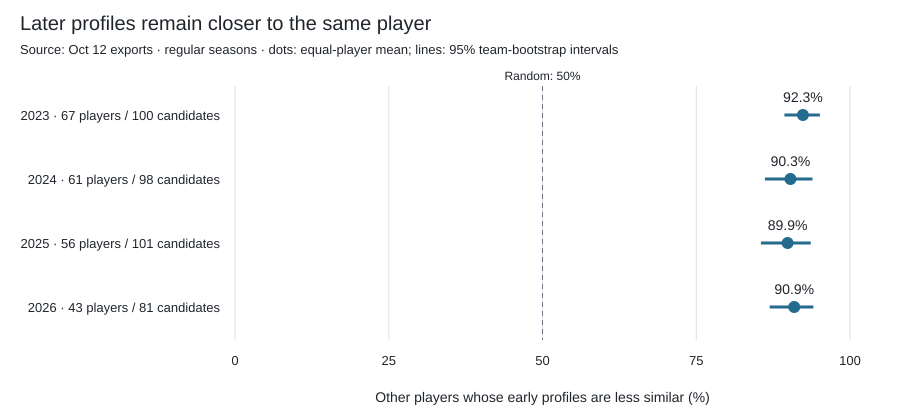

In [3]:
from html import escape

class SVGFigure:
    def __init__(self, value): self.value = value
    def _repr_svg_(self): return self.value

def svg_start(width, height, title, subtitle):
    return [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-label="{escape(title)}">',
        f'<rect width="{width}" height="{height}" fill="white"/>',
        '<g font-family="Arial,sans-serif" fill="#20252b">',
        f'<text x="20" y="30" font-size="20">{escape(title)}</text>',
        f'<text x="20" y="54" font-size="13">{escape(subtitle)}</text>']

def consistency_figure():
    width, height, left, right = 920, 420, 235, 70
    x = lambda value: left + value*(width-left-right)
    parts = svg_start(width, height, 'Later profiles remain closer to the same player',
        'Source: Oct 12 exports · regular seasons · dots: equal-player mean; lines: 95% team-bootstrap intervals')
    for value in [0,.25,.5,.75,1]:
        xx=x(value)
        parts += [f'<line x1="{xx}" x2="{xx}" y1="86" y2="340" stroke="#dce1e5"/>',
            f'<text x="{xx}" y="365" font-size="13" text-anchor="middle">{value*100:.0f}</text>']
    parts.append(f'<line x1="{x(.5)}" x2="{x(.5)}" y1="86" y2="340" stroke="#6b7280" stroke-dasharray="5 4"/>')
    parts.append(f'<text x="{x(.5)}" y="80" text-anchor="middle" font-size="12">Random: 50%</text>')
    for i,s in enumerate(result['studies']):
        y=115+64*i
        m=s['fractionOfOtherPlayersBeaten']; low,high=m['ci95']
        label=f"{s['season']} · {s['evaluatedPlayers']} players / {s['referencePlayers']} candidates"
        parts += [f'<text x="{left-15}" y="{y+5}" text-anchor="end" font-size="13">{escape(label)}</text>',
            f'<line x1="{x(low)}" x2="{x(high)}" y1="{y}" y2="{y}" stroke="#246b8e" stroke-width="3"/>',
            f'<circle cx="{x(m["mean"])}" cy="{y}" r="6" fill="#246b8e"/>',
            f'<text x="{x(m["mean"])}" y="{y-13}" font-size="14" text-anchor="middle">{m["mean"]*100:.1f}%</text>']
    parts.append(f'<text x="{(left+width-right)/2}" y="402" font-size="14" text-anchor="middle">Other players whose early profiles are less similar (%)</text></g></svg>')
    return SVGFigure(''.join(parts))

consistency_figure()

In [4]:
rows = []
for s in result['studies']:
    rows.append({'Season':s['season'], 'Evaluated players':s['evaluatedPlayers'],
        'Early candidates':s['referencePlayers'], 'Self closest (%)':round(s['top1']['mean']*100,1),
        'Random closest (%)':round(s['randomTop1']*100,1),
        'Self in top five (%)':round(s['top5']['mean']*100,1),
        'Within-team self closest (%)':round(s['withinTeamTop1']['mean']*100,1),
        'Within-team random (%)':round(s['withinTeamRandomTop1']*100,1)})
pd.DataFrame(rows).set_index('Season')

,Evaluated players,Early candidates,Self closest (%),Random closest (%),Self in top five (%),Within-team self closest (%),Within-team random (%)
Season,,,,,,,
2023,67,100,34.3,1.0,61.2,73.1,18.8
2024,61,98,23.0,1.0,49.2,53.2,17.0
2025,56,101,26.8,1.0,53.6,66.7,18.2
2026,43,81,23.3,1.2,60.5,71.9,20.9


**Interpretation:** Persistence is not just a team fingerprint: the within-team check is also above its random baseline. In 2026 it includes 32 players across 13 teams, with 4–7 earlier candidates per team. Its 71.9% self-match estimate has a wide 48.1–90.9% interval. The full-cohort top-five result is 26/43, or 60.5%; random top-five selection among 81 candidates would average 6.2%. These are different metrics with different denominators.

The main cohort contributes 7,570 earlier and 9,043 later throws. The 100-catch threshold strongly favors regularly involved players. It does not support labeling every player in the database.

### 2. Which traits persist most?
Rank correlation asks whether players who are high on a trait earlier also tend to be high later. A value of 1 means the ranking is unchanged; 0 means no rank relationship. It does not measure completion or model accuracy.

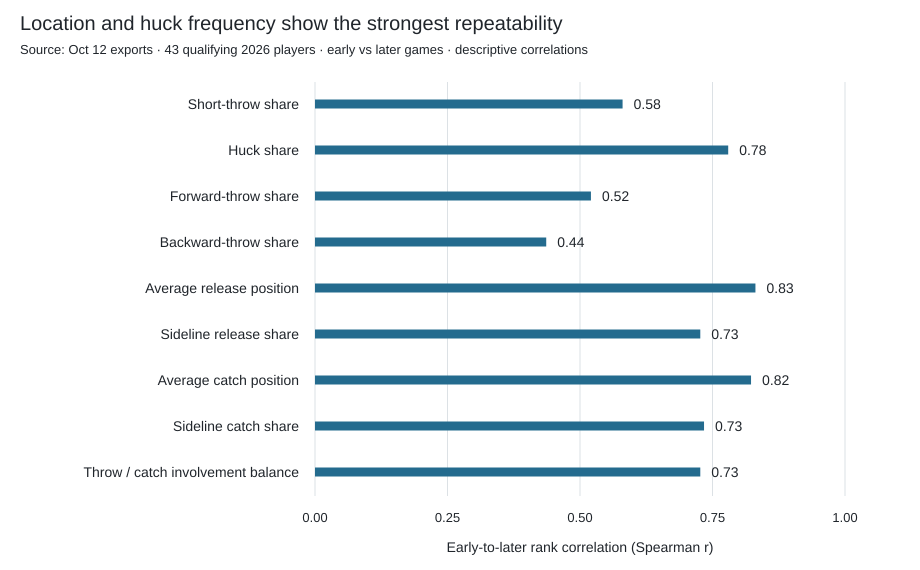

In [5]:
def trait_figure():
    labels = {'shortShare':'Short-throw share', 'huckShare':'Huck share',
        'forwardShare':'Forward-throw share', 'backwardShare':'Backward-throw share',
        'releaseY':'Average release position', 'releaseSide':'Sideline release share',
        'catchY':'Average catch position', 'catchSide':'Sideline catch share',
        'throwShare':'Throw / catch involvement balance'}
    width, height, left, right = 920, 570, 315, 75
    x = lambda value: left + value*(width-left-right)
    parts = svg_start(width, height, 'Location and huck frequency show the strongest repeatability',
        'Source: Oct 12 exports · 43 qualifying 2026 players · early vs later games · descriptive correlations')
    for tick in [0,.25,.5,.75,1]:
        parts += [f'<line x1="{x(tick)}" x2="{x(tick)}" y1="82" y2="496" stroke="#dce1e5"/>',
            f'<text x="{x(tick)}" y="522" font-size="13" text-anchor="middle">{tick:.2f}</text>']
    for i,r in enumerate(primary['featureStability']):
        y=104+i*46
        parts += [f'<text x="{left-16}" y="{y+5}" text-anchor="end" font-size="14">{escape(labels[r["feature"]])}</text>',
            f'<line x1="{x(0)}" x2="{x(r["spearman"])}" y1="{y}" y2="{y}" stroke="#246b8e" stroke-width="9"/>',
            f'<text x="{x(r["spearman"])+11}" y="{y+5}" font-size="14">{r["spearman"]:.2f}</text>']
    parts.append(f'<text x="{(left+width-right)/2}" y="552" text-anchor="middle" font-size="14">Early-to-later rank correlation (Spearman r)</text></g></svg>')
    return SVGFigure(''.join(parts))

trait_figure()

Average release position (0.83), catch position (0.82) and huck share (0.78) are the most repeatable of these nine traits in the primary cohort. Backward-throw share is weaker (0.44). This supports keeping hucks as one descriptive component rather than abandoning them entirely.

The overall match does not depend on only one feature group: removing any of the four groups still leaves average self-similarity percentiles of 85.7–93.2%. Passing choices alone reach 81.9%. These checks assess robustness; their results were not used to choose new weights or declare an optimal model.

### 3. Similar players also tend to stay relatively similar
This is a follow-up added **after** the positive self-matching result. Using early profiles, select each player's five closest peers from other teams among players qualified in both periods. Then rank those selected peers using only later profiles, on the same scale learned earlier. This directly checks a first step toward a comparison tool.

Randomly selected peers would average the 50th later-similarity percentile. The selected peers average 69.9 in the primary sample and 74.2 in the broader sample. Higher means more similar. A percentile is not a percentage of correctly recommended replacements.

In [6]:
pd.DataFrame([{'Minimum throws AND catches per period':floor,
               'Players evaluated':result['neighborFollowup'][key]['evaluatedPlayers'],
               'Chosen peers per player':5,
               'Mean later similarity percentile':round(result['neighborFollowup'][key]['meanLaterSimilarityPercentile']*100,1),
               'Random expected percentile':50.0}
              for floor,key in [(100,'primary100'),(50,'broader50')]])

,Minimum throws AND catches per period,Players evaluated,Chosen peers per player,Mean later similarity percentile,Random expected percentile
0,100,43,5,69.9,50.0
1,50,146,5,74.2,50.0


The selected pairs overlap and share opponents and team contexts, so no confidence interval assuming independent pairs is shown. This is preliminary evidence for persistent similarity; a future-season test is still needed before using similarity scores for consequential roster decisions.

The broader 50-event sample has 224 earlier candidates and 146 evaluated players. Its own-profile percentile is 90.5% (88.4–92.6%), and within-team identification is 52.1% versus a 10.3% random baseline. The 150-event floor leaves only 12 evaluated players across nine teams; it is too restrictive for a useful general conclusion.

Across 2025→2026, 44 qualifying players have an average own-profile percentile of 86.8% (81.8–91.1%), with 7/44 nearest matches among 102 earlier candidates. Seven players changed teams; that subgroup is too small to validate transfer or replacement performance. The season-to-season check is encouraging but overlaps the primary players and later-season data.

### 4. Concrete examples: stable tendencies can coexist with changing locations
Alex Atkins and Oscar Graff were selected from players already discussed in this project, not because they had the best matching results. Both pass the main sample floor. Their earlier and later profiles show why a comparison should expose the component traits and counts rather than assign a permanent label.

In [7]:
examples = {p['name']:p for p in result['examples']}
example_rows = []
for name in ['Alex Atkins','Oscar Graff']:
    p = examples[name]
    for period in ['early','later']:
        s=p[period]
        example_rows.append({'Player':name, 'Period':period,
            'Throws':s['throws'], 'Completed catches':s['catches'],
            'Short throws (%)':round(s['shortShare']*100,1),
            'Hucks / throws':f"{round(s['huckShare']*s['throws'])}/{s['throws']}",
            'Huck share (%)':round(s['huckShare']*100,1),
            'Average release Y (yd)':round(s['releaseY'],1),
            'Average catch Y (yd)':round(s['catchY'],1)})
pd.DataFrame(example_rows).set_index(['Player','Period'])

Throws  ...  Average catch Y (yd)
Player      Period          ...                      
Alex Atkins early      227  ...                  54.5
            later      205  ...                  47.0
Oscar Graff early      136  ...                  62.0
            later      163  ...                  68.2

[4 rows x 7 columns]

Atkins hucked on 8.8% of earlier throws and 7.3% later, while his average release moved from Y48.4 to Y39.5. Graff's short-throw share moved from 39.7% to 34.4%, while his average release moved from Y57.1 to Y66.6. Their own earlier profiles ranked 18th and second respectively among 81 candidates. These are examples of descriptive continuity and change, not evidence that the players should change roles.

These profiles measure what players did with the disc, not how effective a replacement would be. A later effectiveness panel should compare outcomes on suitably comparable throws, show uncertainty, and remain separate from playing style. This pilot does not rank thrower aEC per attempt or use it to select neighbors.

## Takeaways
- **Proceed with a comparison prototype for sufficiently observed players.** Keep pass choices, release/catch locations and event counts visible; let a coach see why two profiles appear similar.
- **Use the question “Which players have similar recorded offensive tendencies, and where do they differ?”** It has a defensible first result and a concrete scouting use.
- **Keep hucks as one trait.** Their frequency can be consistent even though individual preferred huck-success zones were not established in the earlier study.
- **Do not assign fixed archetypes yet.** Repeatable continuous differences do not prove that the league separates into distinct clusters. Cluster stability and useful coach interpretations require their own test.
- **Do not claim roster interchangeability.** This test contains no lineup outcomes, on-field exposure, tracked routes, marking, pressure or film evaluation. Similar passing style is a candidate-screening aid.
- **Next validation:** freeze these definitions and test the comparison on newly available games or a new season, then ask coaches whether the suggested comparisons help them locate useful film or evaluate a missing role.

Reproducible files: `analysis/passing_profile_validation.py`, its aggregate JSON, and `analysis/passing_profile_checks.py`. This notebook saves executed outputs and embedded figures. The raw CSVs remain local and excluded from Git. The existing website was not changed by this pilot.